# Self-RAG Step 3: Grounded Answer Generation

![Self-RAG Answer Generation Workflow.png](<attachment:Self-RAG Answer Generation Workflow.png>)

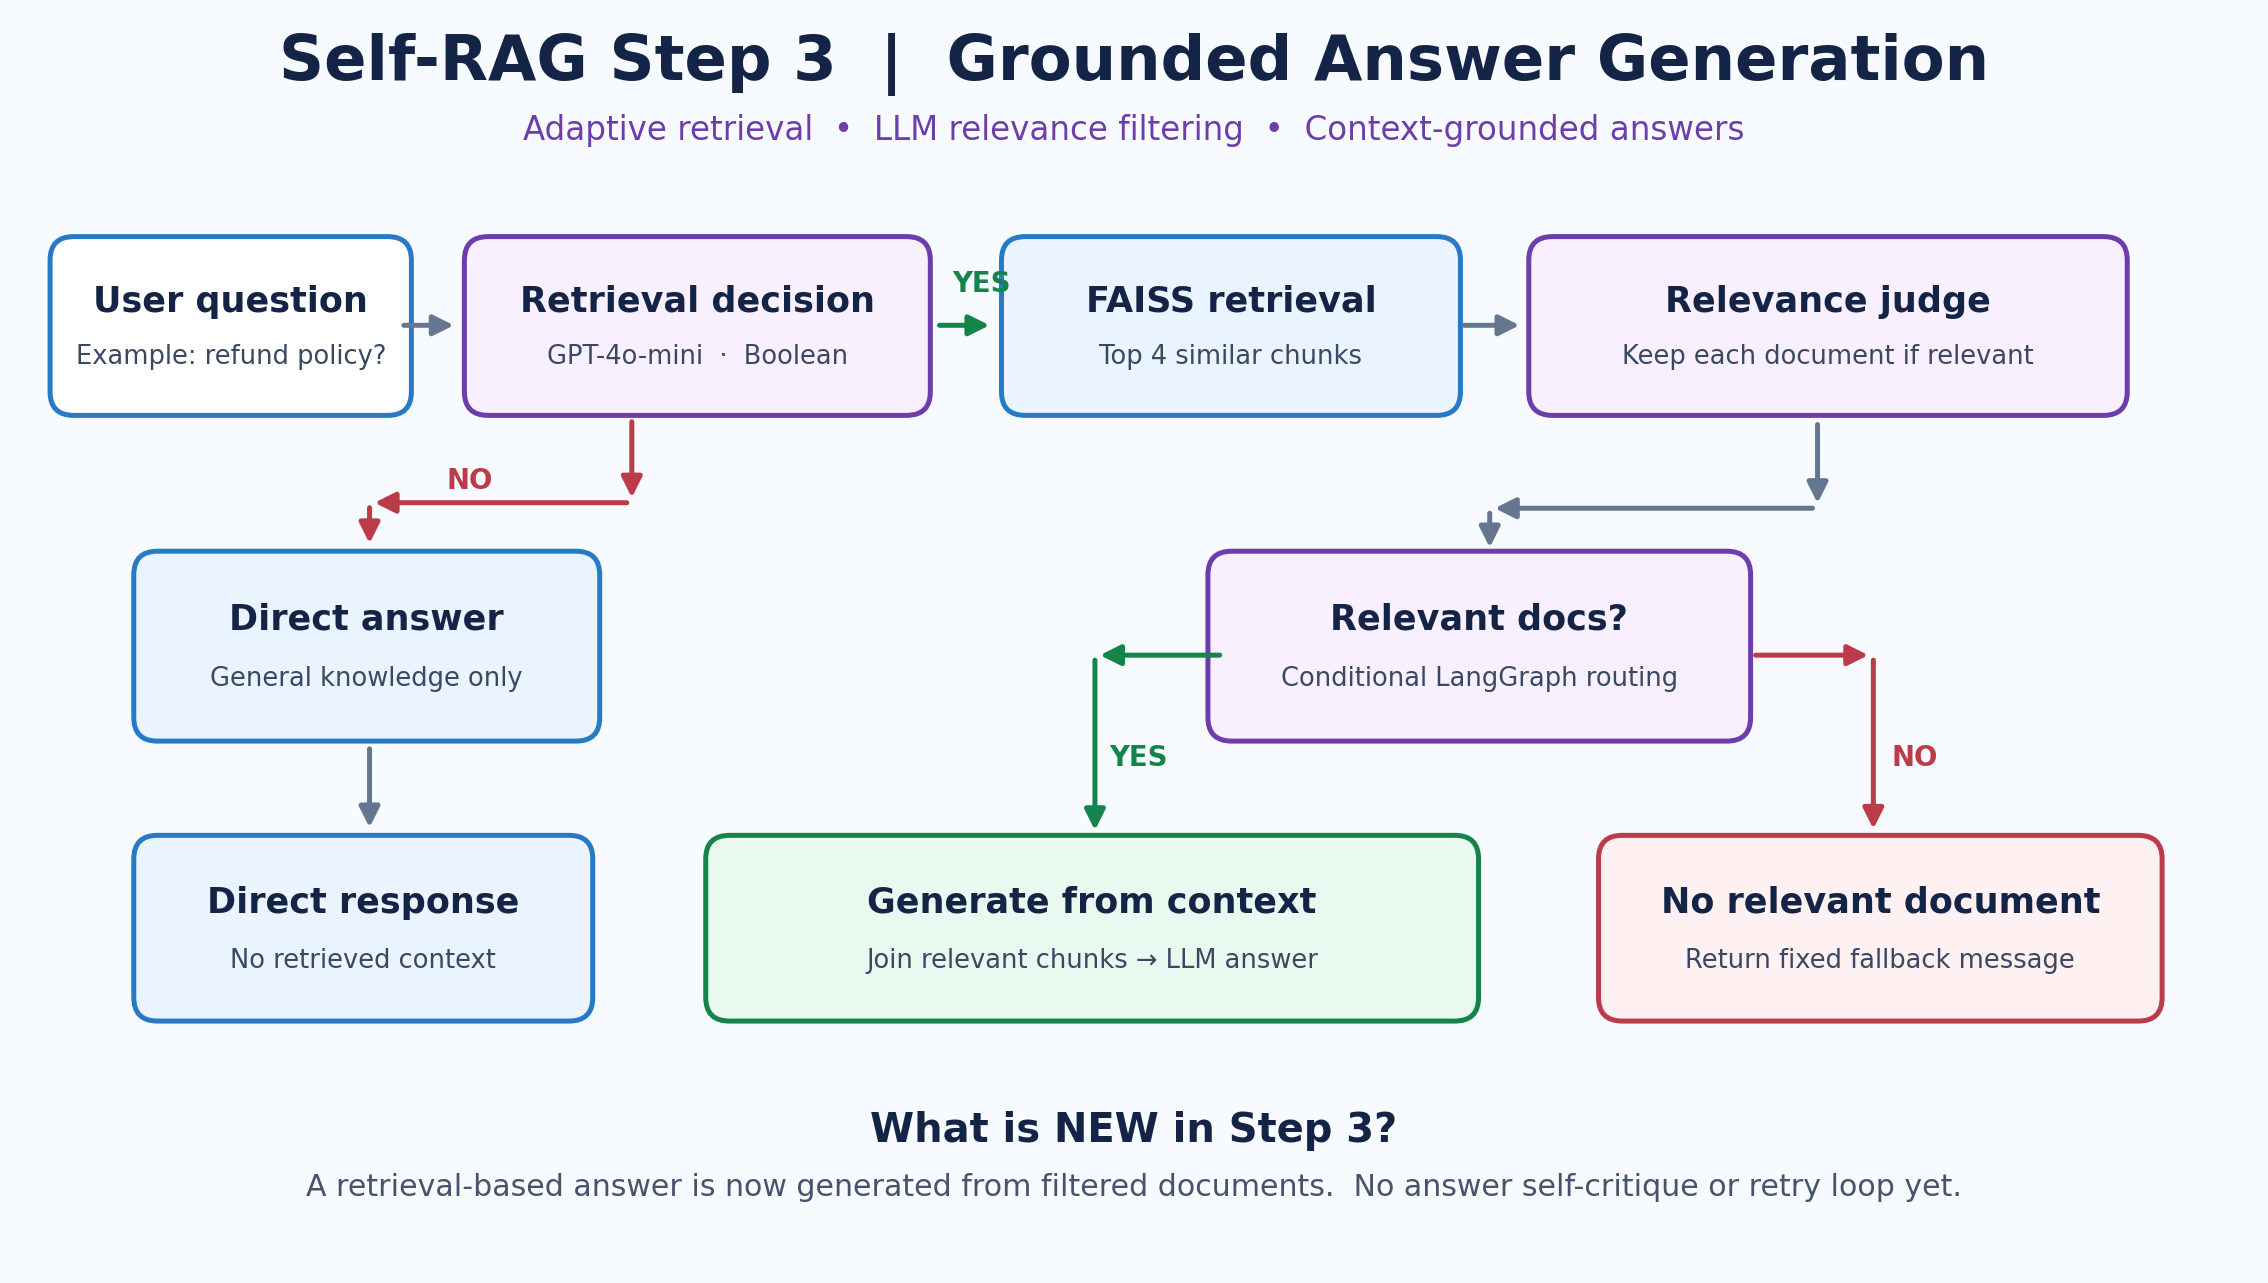
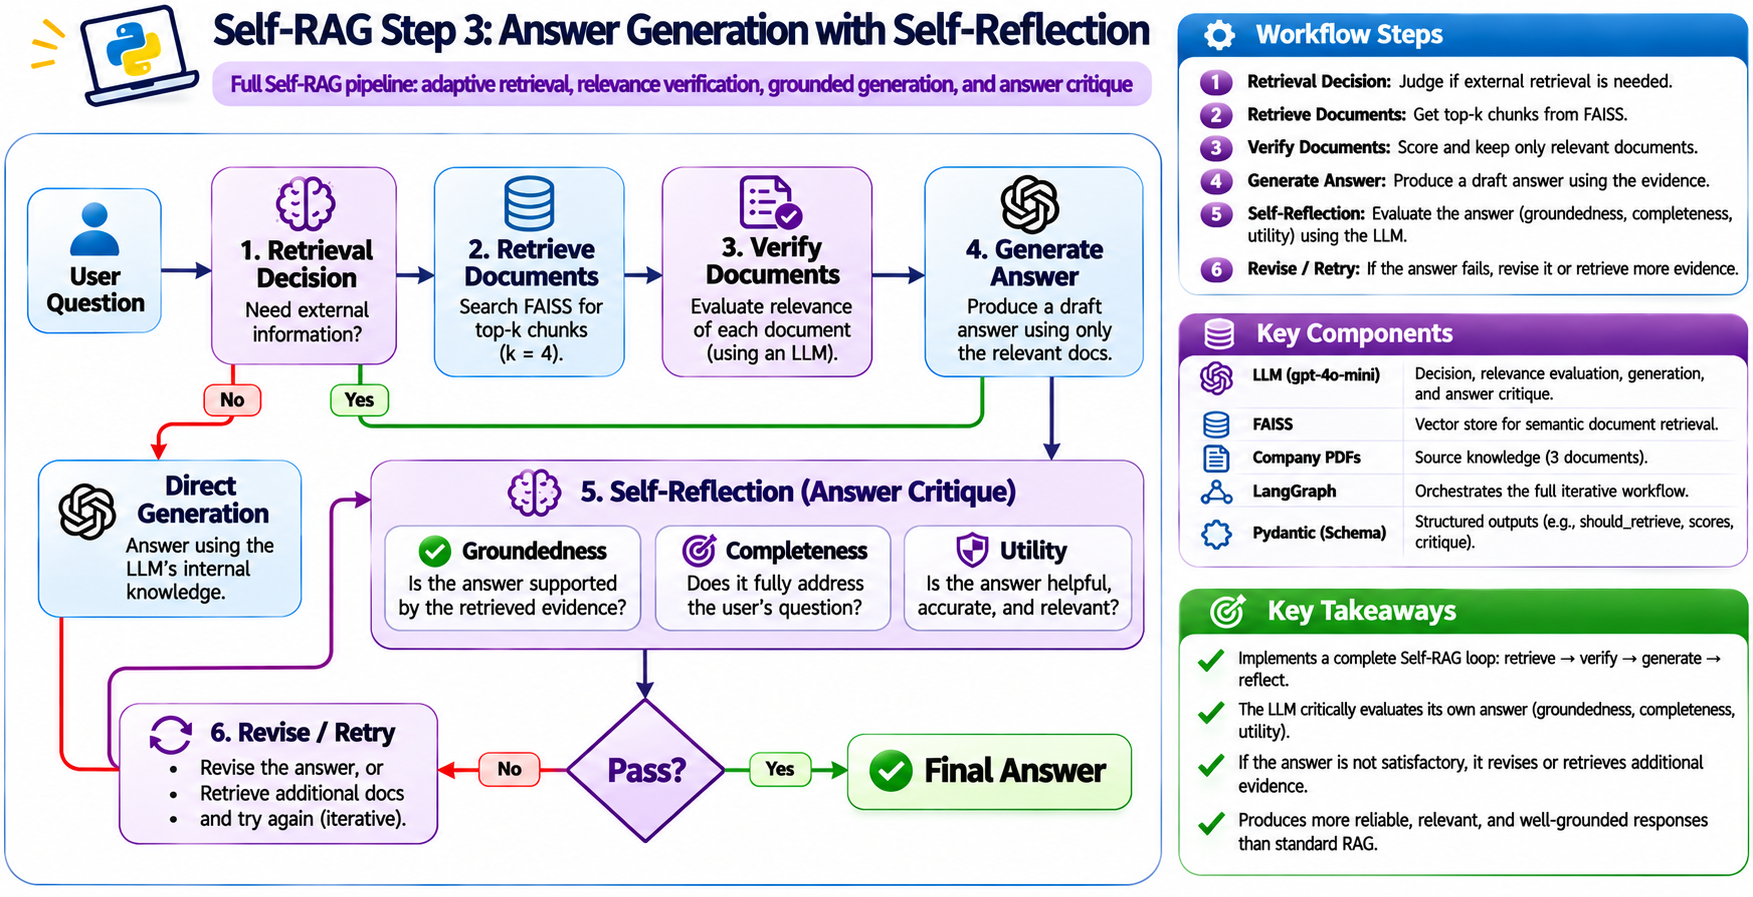


This notebook extends Self-RAG Step 2 by introducing **context-grounded answer generation** using LangGraph, FAISS, and GPT-4o-mini.

### 1. Knowledge Base

- Load three company PDFs using `PyPDFLoader`, or load a saved FAISS index.
- Split documents into chunks (`chunk_size=600`, `chunk_overlap=150`) when building the index.
- Generate embeddings using `all-MiniLM-L6-v2`.
- Retrieve the top 4 similar chunks from FAISS.

### 2. Adaptive Retrieval and Relevance Evaluation

The LLM performs two decisions:

- **Retrieval Decision:** Determine whether external documents are necessary.
- **Relevance Evaluation:** Check each retrieved chunk and keep only relevant documents in `relevant_docs`.

### 3. Grounded Answer Generation (New)

The `generate_from_context()` node combines relevant documents into `context` and generates an answer using only that evidence.

If no relevant documents are available, the workflow returns `"No relevant document found."`

### 4. LangGraph Workflow

```text
START → decide_retrieval
              │
       ┌──────┴──────┐
       ▼             ▼
      False         True
       │             │
 generate_direct   retrieve
       │             │
      END        is_relevant
                     │
              Relevant docs?
                /        \
              Yes         No
               │           │
      generate_from_    no_relevant_
         context           docs
               │           │
              END         END
```

### 5. Key Takeaway

**Step 3 completes the retrieval-to-answer workflow by generating responses from LLM-filtered documents.**

Unlike Step 2, retrieved information is now used to produce an answer.

**Current limitation:** The system does not yet perform answer-level self-reflection, groundedness verification, or iterative correction. These can be introduced in the next stage.

In [1]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load API credentials and configuration from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_3368\3222129094.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1103 08:02:46.724000 3368 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 08:02:46.934000 3368 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [2]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [3]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [4]:
# --------------------------------------------------
# Graph State
# --------------------------------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]
    relevant_docs: List[Document]     

    context: str # New
    answer: str

In [ ]:
# -----------------------------
# 1) Decide retrieval
# -----------------------------

# Structured model result for deciding whether retrieval is needed.
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)


# IMPORTANT: no `.content` for structured output
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "State"):
    # Decide whether this question needs facts from the local documents.
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    # Store the retrieval decision in the graph state for routing.
    return {"need_retrieval": decision.should_retrieve}

In [ ]:
# -----------------------------
# 2) Direct answer (no retrieval)
# -----------------------------

direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


# Answer general questions without consulting the document collection.
def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }


In [ ]:
# -----------------------------
# 3) Retrieve
# -----------------------------

# Search the FAISS index using the rewritten query when available.
def retrieve(state: State):
    # Save retrieved document chunks in graph state.
    return {"docs": retriever.invoke(state["question"])}

In [ ]:
# -----------------------------
# 4) Relevance filter 
# -----------------------------

# Structured yes/no judgment for each retrieved document.
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True if the document helps answer the question, else False."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

# Return a validated relevance decision instead of free-form text.
relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    
    relevant_docs: List[Document] = []

    # Evaluate each retrieved chunk against the original question.
    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        # Keep only documents the model considers useful evidence.
        if decision.is_relevant:
            relevant_docs.append(doc)

    # Pass the filtered evidence to the next graph node.
    return {"relevant_docs": relevant_docs}



In [ ]:
# -----------------------------
# 5) Generate from context
# -----------------------------
# New
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business RAG assistant.\n"
            "Answer the user's question using ONLY the provided context.\n"
            "If the context does not contain enough information, say:\n"
            "'No relevant document found.'\n"
            "Do not use outside knowledge.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

def generate_from_context(state: State):
    # Stuff relevant docs into one block
    context = "\n\n---\n\n".join(
        [d.page_content for d in state.get("relevant_docs", [])]
    ).strip()

    # Avoid generating a context-based answer when there is no evidence.
    if not context:
        return {"answer": "No relevant document found.", "context": ""}

    out = llm.invoke(
        rag_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": out.content, "context": context}


In [10]:
# New
def no_relevant_docs(state: State):
    return {"answer": "No relevant document found.", "context": ""}

In [11]:
# Select direct answering or retrieval based on the decision in state.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [12]:
# New
def route_after_relevance(state: State) -> Literal["generate_from_context", "no_relevant_docs"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_from_context"
    return "no_relevant_docs"


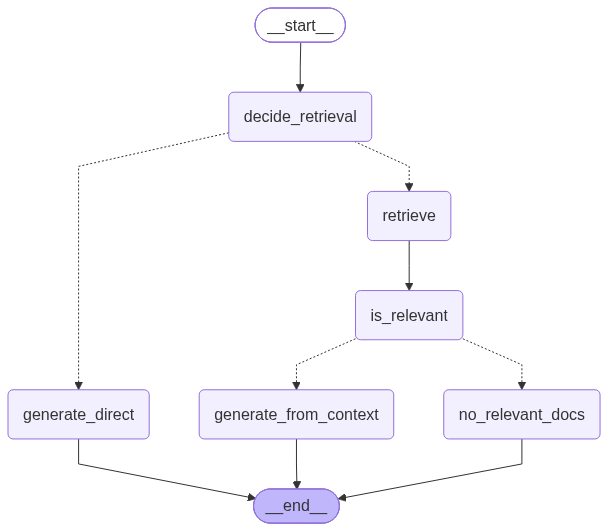

In [13]:
# Create the LangGraph workflow with the shared state schema.
g = StateGraph(State)

g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)
g.add_node("is_relevant", is_relevant)
g.add_node("generate_from_context", generate_from_context)
g.add_node("no_relevant_docs", no_relevant_docs)

# Set the first node that runs when the graph is invoked.
g.add_edge(START, "decide_retrieval")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("generate_direct", END)

g.add_edge("retrieve", "is_relevant")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {
        "generate_from_context": "generate_from_context",
        "no_relevant_docs": "no_relevant_docs",
    },
)

g.add_edge("generate_from_context", END)
g.add_edge("no_relevant_docs", END)

# Compile the nodes and edges into an executable graph.
app = g.compile()

app

In [14]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
    {
        "question": "What is the refund policy of DSwithBappy",
        "docs": [],
        "relevant_docs": [],
        "context": "",
        "answer": "",
    }
)

print(result["answer"])

No relevant document found.


In [20]:
print(result["need_retrieval"])
print(result["docs"])

True
[Document(id='2dfb0392-2a17-490f-a4f8-72101ef621cd', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-08-26T04:40:11+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-08-26T04:40:11+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './documents/DSwithBappy_Company_Policies.pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}, page_content='DSwithBappy - Company Policies\nHR Policies\nDSwithBappy is committed to maintaining a fair, inclusive, collaborative, and\nperformance-driven workplace.\nAll employment and team decisions are made fairly and without discrimination.\n●\nEqual opportunity workplace\n●\nBi-annual performance and growth reviews\n●\nClear career and skill progression framework\n●\nStrict anti-harassment and respectful-workplace policy\nLeave Policy\nTeam members are encouraged to maintain a healthy work-life balance.\n●\nAnnual Leave: 18 working d

In [21]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
    {
        "question": "Who is the Founder of DSwithBappy?",
        "docs": [],
        "relevant_docs": [],
        "context": "",
        "answer": "",
    }
)

print(result["answer"])

The founder of DSwithBappy is Bappy.


In [22]:
print(result["need_retrieval"])
print(result["docs"])

True
[Document(id='f341c2d6-90a8-49e8-8fcb-00ad0fdf158f', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-08-26T04:40:11+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-08-26T04:40:11+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './documents/DSwithBappy_Company_Profile.pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}, page_content='DSwithBappy - Company Profile\nCompany Overview\nDSwithBappy is an AI education and engineering platform focused on helping learners build\npractical, production-ready skills in artificial intelligence.\nThe platform specializes in hands-on learning across Generative AI, RAG, Agentic AI, LLM\napplications, AI engineering, and deployment.\nDSwithBappy serves students, developers, working professionals, and teams who want to learn\nmodern AI through practical projects and clear explanations.\n●\nFocus: Practical AI education and 

In [15]:
# Who is the Founder of DSwithBappy?
# What is the refund policy of DSwithBappy

In [17]:
for doc in result['relevant_docs']:
    print(doc.page_content)
    print("*"*100)